[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch55_LabCh55_Forecasting_Honestly.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 55: Time Series and Forecasting** (Part XII: Other Shapes of Data).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=55](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=55)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch55 - Forecasting, honestly
## One shop, four years of daily sales, eight forecasters, and three crimes committed on purpose

This lab goes with **Chapter 55** of *The Why Book of Deep Learning, Part 2*.

There is no data file. The lab invents four years of daily sales for one bakery, built from parts you can
see: a trend, a weekly rhythm, a yearly rhythm, public holidays, one day a year when the shop is closed,
noise, and one sudden change of level in the last year. Because we built the series, we know the truth,
and we can check every claim a forecaster makes.

| The miniature | value |
|---|---|
| series | 1,460 daily values (4 years of 365 days), one shop, loaves sold per day |
| history window | the last 28 days |
| horizons | 1 day ahead for most of the lab; 1 to 28 days ahead in Step 16 |
| baselines | last value, seasonal naive (same day last week), 7-day moving average, mean of the last 4 same weekdays |
| models | a linear model on 28 lags (29 numbers), an LSTM (1,169), a 1-D CNN (1,953) |
| exam | walk-forward validation: the last year, in 4 blocks of 91 days, refitting before each block |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Name the parts of a series and measure how much each one moves it | Steps 2 to 4 |
| Turn a series into supervised pairs by windowing, and say the shapes | Step 5 |
| Split by time and set up walk-forward validation | Step 6 |
| Compute the baselines every forecast must beat, with MAE, RMSE, MAPE and MASE | Steps 7 and 8 |
| Fit a linear model, an LSTM and a 1-D CNN on the same windows and compare them fairly | Steps 9 to 14 |
| Use a covariate that is known in advance | Step 15 |
| Forecast 28 days ahead, recursively and directly | Step 16 |
| Turn a forecast into a range and check the range | Step 17 |
| Commit three classic leaks and measure how much each one flatters the model | Steps 18 to 21 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about two minutes on a laptop CPU. Half of it is Step 12 (sixteen small training runs). No GPU is needed and nothing is downloaded.

> **Honest scale:** this is a miniature and the data is invented. One series of 1,460 points is the
> situation in which deep models have the least to offer, and the lab is built to show that fairly. The
> numbers printed here describe this toy. They are not what any model scores on real demand data. What
> carries over is the procedure: baselines first, a split by time, walk-forward validation, MASE, and the
> habit of asking where a suspiciously good number came from.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 55
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=2, suppress=True, linewidth=110)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


## Step 2 - Build a series from parts we can see

Our toy calendar is simple: every year has 365 days and day 0 is a Monday. The sales of day `t` are

`trend + weekly rhythm + yearly rhythm + level shift + noise`, then multiplied by 0.6 on a public holiday
and set to 0 on the one day a year the shop is closed.

The noise has three parts, as real demand does: day-to-day scatter, a mood that lingers for a few days,
and **weekday habits that drift slowly** (this March, Saturdays are a little busier than they were in
January). On day 1,215 a rival shop closes and the level jumps by 35 loaves, for good.

**Predict before you run:** the weekly rhythm swings between -30 and +38 loaves. The trend adds 0.035
loaves a day. Over four years, which of the two moves the series more?

days: 1460 | first two weeks: [106 150 158 197 205 224 230 167 171 191 206 224 239 222]
smallest 0, largest 374, mean 248.3

how far each part moves over four years (largest minus smallest):
  trend      51.1 loaves   (standard deviation  14.8)
  weekly     68.0 loaves   (standard deviation  23.8)
  yearly     52.0 loaves   (standard deviation  18.4)
  shift      35.0 loaves   (standard deviation  13.1)
  mood       39.6 loaves   (standard deviation   6.9)
  habit      45.0 loaves   (standard deviation   7.9)
  scatter    31.3 loaves   (standard deviation   5.2)
public holidays: 28 days | closed: 4 days


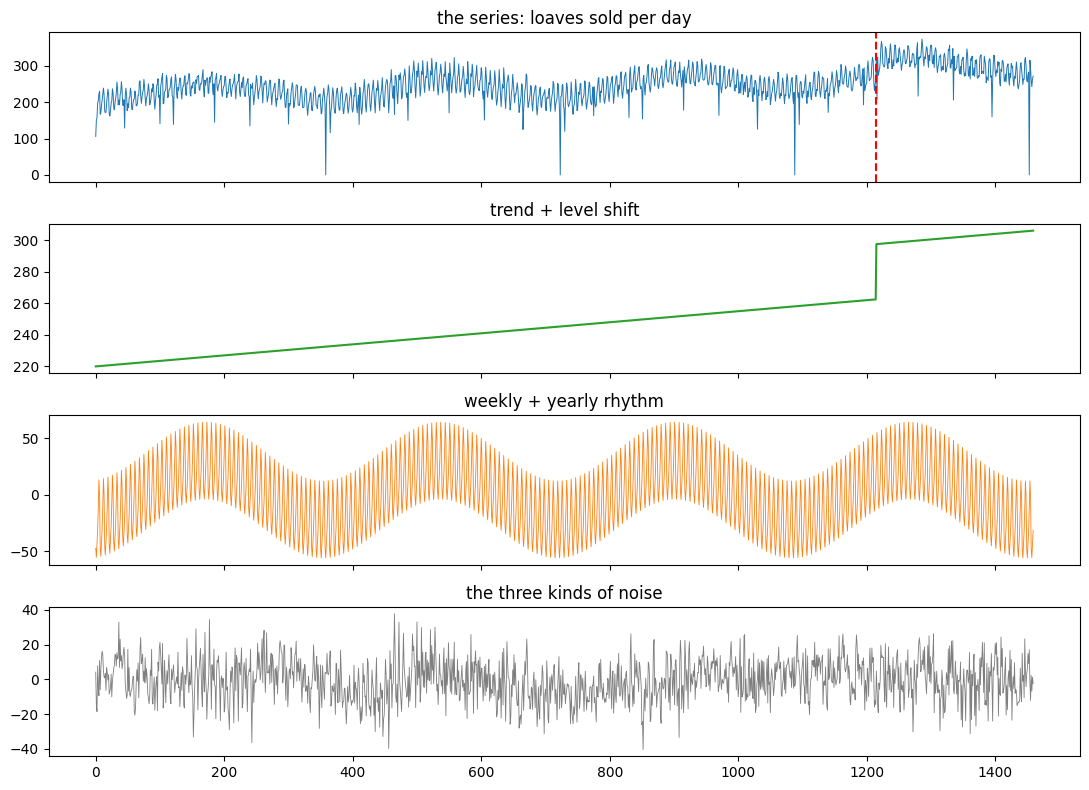

In [2]:
YEARS, YEAR = 4, 365
N = YEARS * YEAR                       # 1,460 days
SHIFT_DAY, SHIFT_SIZE = 1215, 35.0     # a rival closes: the level jumps and stays
HOLIDAYS = [0, 45, 100, 121, 185, 240, 300]   # day of year of 7 public holidays (sales x 0.6)
CLOSED = 358                                  # day of year the shop is shut (sales = 0)
WEEK = np.array([-22., -30., -18., -6., 14., 38., 24.])   # Mon .. Sun

def make_series(seed=SEED):
    rng = np.random.default_rng(seed)
    t = np.arange(N); dow = t % 7; doy = t % YEAR
    trend = 220 + 0.035 * t
    weekly = WEEK[dow]
    yearly = 26 * np.sin(2 * np.pi * (doy - 80) / YEAR)
    shift = np.where(t >= SHIFT_DAY, SHIFT_SIZE, 0.0)
    # noise 1: a mood that lingers (each day keeps 70% of yesterday's mood)
    kick = rng.normal(0, 5, N); mood = np.zeros(N)
    for i in range(1, N):
        mood[i] = 0.7 * mood[i - 1] + kick[i]
    # noise 2: weekday habits drift, one small step a week for each weekday
    step = rng.normal(0, 2.5, (N // 7 + 1, 7)); habit_w = np.zeros_like(step)
    for i in range(1, len(step)):
        habit_w[i] = 0.95 * habit_w[i - 1] + step[i]
    habit = habit_w[t // 7, dow]
    # noise 3: plain day-to-day scatter
    scatter = rng.normal(0, 5, N)
    holiday = np.isin(doy, HOLIDAYS); closed = doy == CLOSED
    y = trend + weekly + yearly + shift + mood + habit + scatter
    y = np.where(holiday, 0.6 * y, y)
    y = np.where(closed, 0.0, y)
    y = np.maximum(0, np.round(y))             # loaves are whole and never negative
    return dict(y=y, t=t, dow=dow, doy=doy, trend=trend, weekly=weekly, yearly=yearly, shift=shift,
                mood=mood, habit=habit, scatter=scatter, holiday=holiday, closed=closed)

S = make_series()
y = S["y"]
print("days:", N, "| first two weeks:", y[:14].astype(int))
print("smallest %d, largest %d, mean %.1f" % (y.min(), y.max(), y.mean()))
print("\nhow far each part moves over four years (largest minus smallest):")
for name in ["trend", "weekly", "yearly", "shift", "mood", "habit", "scatter"]:
    print("  %-8s %6.1f loaves   (standard deviation %5.1f)" % (name, np.ptp(S[name]), S[name].std()))
print("public holidays: %d days | closed: %d days" % (S["holiday"].sum(), S["closed"].sum()))

fig, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
ax[0].plot(y, lw=0.7); ax[0].axvline(SHIFT_DAY, color="r", ls="--"); ax[0].set_title("the series: loaves sold per day")
ax[1].plot(S["trend"] + S["shift"], color="tab:green"); ax[1].set_title("trend + level shift")
ax[2].plot(S["weekly"] + S["yearly"], lw=0.6, color="tab:orange"); ax[2].set_title("weekly + yearly rhythm")
ax[3].plot(S["mood"] + S["habit"] + S["scatter"], lw=0.6, color="tab:grey"); ax[3].set_title("the three kinds of noise")
plt.tight_layout(); plt.show()

### Why we see this

The weekly rhythm has the larger swing from one day to the next (68 loaves between a Tuesday and a
Saturday), and the trend the larger effect over the whole record: 0.035 a day is 51 loaves in four years.
A series is a sum of things that move at different speeds, and each speed needs its own treatment. The
fast, regular part is the easiest to forecast. The slow part is easy until it changes. The level shift is
the kind of event no model can foresee, and all of them must recover from.

---
## Step 3 - Neighbours are correlated: the autocorrelation

In a table of customers, row 17 tells you nothing about row 18. In a time series, yesterday tells you a
great deal about today. The **autocorrelation at lag k** is the correlation between the series and a copy
of itself moved k days.

**Predict before you run:** which is larger, the autocorrelation at lag 1 (yesterday) or at lag 7 (the
same weekday last week)?

lag   autocorrelation
   1   +0.675   ###########################
   2   +0.482   ###################
   3   +0.364   ###############
   6   +0.649   ##########################
   7   +0.810   ################################
   8   +0.666   ###########################
  14   +0.785   ###############################
  28   +0.756   ##############################
 364   +0.681   ###########################
 365   +0.745   ##############################


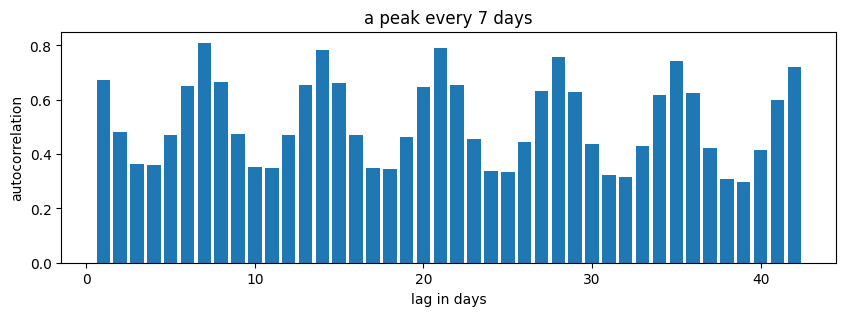

In [3]:
def autocorr(s, k):
    return float(np.corrcoef(s[:-k], s[k:])[0, 1])

print("lag   autocorrelation")
for k in [1, 2, 3, 6, 7, 8, 14, 28, 364, 365]:
    print("%4d   %+.3f   %s" % (k, autocorr(y, k), "#" * int(round(40 * max(0, autocorr(y, k))))))

plt.figure(figsize=(10, 3))
plt.bar(range(1, 43), [autocorr(y, k) for k in range(1, 43)]); plt.xlabel("lag in days"); plt.ylabel("autocorrelation")
plt.title("a peak every 7 days"); plt.show()

### Why we see this

Lag 7 wins, and so do 14 and 28: a Saturday resembles other Saturdays far more than it resembles the Friday
before it. The peaks every seven days are the weekly rhythm seen through this instrument. Two consequences
follow. A forecast that copies yesterday is a poor baseline for this series, and one that copies last week
is a strong one. And because neighbouring days share so much, 1,460 days carry much less independent
evidence than 1,460 separate customers would.

---
## Step 4 - Stationary, in plain words: do the rules stay the same?

A series is called **stationary** when its level and its spread do not change as time passes: any stretch
looks statistically like any other. Ours is not. It climbs, and it jumps. A classical trick is to forecast
the **change** instead of the level, because the change is far better behaved.

**Predict before you run:** the series has a standard deviation of about 44 loaves. What is the standard
deviation of `today minus the same day last week`?

In [4]:
print("mean of each year:", [round(float(y[k * YEAR:(k + 1) * YEAR].mean()), 1) for k in range(YEARS)])
d1 = y[1:] - y[:-1]
d7 = y[7:] - y[:-7]
print("\n                               mean   standard deviation")
print("the series                   %6.1f   %6.1f" % (y.mean(), y.std()))
print("today minus yesterday        %6.2f   %6.1f" % (d1.mean(), d1.std()))
print("today minus 7 days ago       %6.2f   %6.1f" % (d7.mean(), d7.std()))
print("\nmean of the 7-day change in each year:", [round(float(d7[max(0, k * YEAR - 7):(k + 1) * YEAR - 7].mean()), 2) for k in range(YEARS)])

mean of each year: [225.7, 233.7, 247.9, 286.0]

                               mean   standard deviation
the series                    248.3     44.3
today minus yesterday          0.11     35.7
today minus 7 days ago         0.26     27.1

mean of the 7-day change in each year: [0.12, -0.04, 0.46, 0.5]


### Why we see this

Subtracting last week's value removes the weekly rhythm completely and leaves almost none of the trend
(seven days of trend is a quarter of a loaf). What remains has a steady mean close to zero in every year:
it is close to stationary, although the raw series is not. That is **differencing**, and it is why "same
as last week" is such a natural forecast: it is the statement that the seasonal difference is zero on
average. Subtracting yesterday does worse here, because it leaves the whole weekly swing in.

---
## Step 5 - Windowing: a series becomes a table of questions and answers

A network needs pairs: an input and the right answer. We cut them from the series with a sliding frame:
the **history window** (the last `L = 28` days) is the input and the value `h` days after the window is
the answer. `h` is the **horizon**. Chapters 19 and 20 did this for their labs without comment.

**Predict before you run:** with 1,460 days, a window of 28 and a horizon of 1, how many pairs are there?
What shape does Keras want for a recurrent or convolutional layer?

In [5]:
L = 28                                  # history window, in days

def make_windows(series, L, h=1):
    """X[i] = series[i : i+L], Y[i] = the value h days after the window, T[i] = the day index of that answer."""
    n = len(series) - L - h + 1
    X = np.stack([series[i:i + L] for i in range(n)])
    T = np.arange(n) + L + h - 1
    return X, series[T], T

X, Y, T = make_windows(y, L)
print("X", X.shape, "| Y", Y.shape, "| pairs = 1460 - 28 - 1 + 1 =", N - L - 1 + 1)
print("for an LSTM or Conv1D: (batch, timesteps, features) =", X[..., None].shape)
i = 500
print("\npair %d: window covers days %d to %d, answer is day %d" % (i, i, i + L - 1, T[i]))
print("  last 7 inputs:", X[i, -7:].astype(int), "-> answer", int(Y[i]), "| check y[%d] = %d" % (T[i], y[T[i]]))
assert X.shape == (1432, 28) and np.all(X[i] == y[i:i + L]) and Y[i] == y[i + L]

X (1432, 28) | Y (1432,) | pairs = 1460 - 28 - 1 + 1 = 1432
for an LSTM or Conv1D: (batch, timesteps, features) = (1432, 28, 1)

pair 500: window covers days 500 to 527, answer is day 528
  last 7 inputs: [286 275 321 293 257 231 255] -> answer 288 | check y[528] = 288


### Why we see this

1,432 pairs, each `(28,)` in and one number out, or `(28, 1)` once the features axis is added: 28
timesteps, 1 feature per step. Neighbouring pairs overlap in 27 of their 28 inputs, and the answer of pair
500 is an input of pairs 501 to 528. Hold on to that fact. It is harmless while time runs forward and it is
the whole mechanism of the first crime in Step 18.

---
## Step 6 - Split by time, then walk forward

The test set of a forecaster is the future. So the split is a cut in time: everything before the cut is
for fitting, everything after it is the exam. One cut gives one exam, and one exam can be lucky. **Walk-
forward validation** (also called rolling-origin) repeats the cut: fit on the past, forecast the next
block, then move the cut forward, add that block to the past, refit, and forecast the following block.

We keep the last year as the exam, in 4 blocks of 91 days. We assign a pair to "past" or "exam" by the
day of its **answer**, never by where its window starts.

**Predict before you run:** the level shift is on day 1,215. Which block will it fall in, and which
models will have seen it when they are fitted?

In [6]:
BLOCK = 91
FOLDS = [(N - 4 * BLOCK + k * BLOCK, N - 4 * BLOCK + (k + 1) * BLOCK) for k in range(4)]
EXAM0 = FOLDS[0][0]                     # first day of the exam year: 1096

def masks(a, b):
    """Pairs whose answer is before day a are for fitting; pairs whose answer is in [a, b) are the exam."""
    return T < a, (T >= a) & (T < b)

print("block   fit on answers of days   exam days       pairs to fit   pairs in exam   shift (day 1215)")
for k, (a, b) in enumerate(FOLDS):
    tr, te = masks(a, b)
    where = "inside this exam" if a <= SHIFT_DAY < b else ("not yet happened" if SHIFT_DAY >= b else "already in the past")
    print("  %d       %4d to %4d            %4d to %4d    %5d          %4d            %s" % (k + 1, L, a - 1, a, b - 1, tr.sum(), te.sum(), where))

block   fit on answers of days   exam days       pairs to fit   pairs in exam   shift (day 1215)
  1         28 to 1095            1096 to 1186     1068            91            not yet happened
  2         28 to 1186            1187 to 1277     1159            91            inside this exam
  3         28 to 1277            1278 to 1368     1250            91            already in the past
  4         28 to 1368            1369 to 1459     1341            91            already in the past


### Why we see this

The shift lands in block 2. Block 1 is an ordinary quarter. In block 2 every model is fitted on a world
that is about to change. From block 3 on, the fitting data contains some days after the shift. Four blocks
give four scores, and their spread tells you how much one score can be trusted.

---
## Step 7 - Baselines first, and four ways to keep score

Before any model, the forecasts that need no model:

* **last value**: tomorrow will be like today;
* **seasonal naive**: tomorrow will be like the same weekday last week;
* **moving average**: tomorrow will be the mean of the last 7 days;
* **weekday mean**: the mean of the last 4 same weekdays (a smoother seasonal naive).

And the scores. With `e = answer - forecast`:

* **MAE**: the mean of `|e|`, in loaves;
* **RMSE**: the root of the mean of `e squared`, in loaves; it punishes large misses more;
* **MAPE**: the mean of `|e| / answer`, as a percentage;
* **MASE**: MAE divided by the MAE of the seasonal-naive forecast on the fitting data. Below 1 means you
  beat "same as last week". (The original definition, Hyndman and Koehler 2006, scales by a naive
  forecast; for seasonal data the seasonal naive is the usual choice, and it is the one we use.)

**Predict before you run:** rank the four baselines. And what will MAPE do on the day the shop is closed?

In [7]:
def mae(a, f):  return float(np.mean(np.abs(a - f)))
def rmse(a, f): return float(np.sqrt(np.mean((a - f) ** 2)))
def mape(a, f):
    with np.errstate(divide="ignore", invalid="ignore"):
        return float(np.mean(np.abs(a - f) / a) * 100)
def naive_scale(a, m=7):
    """MAE of the seasonal-naive forecast on the fitting data (days before a)."""
    return mae(y[m:a], y[:a - m])
def mase(a_true, f, a):
    return mae(a_true, f) / naive_scale(a)

BASELINES = {
    "last value":      lambda X: X[:, -1],
    "seasonal naive":  lambda X: X[:, -7],
    "moving average":  lambda X: X[:, -7:].mean(axis=1),
    "weekday mean":    lambda X: X[:, [-7, -14, -21, -28]].mean(axis=1),
}
scores = {}                             # scores[name] = list of MAE, one per block
print("MAE in each block                 1       2       3       4     mean    MASE    RMSE    MAPE")
for name, f in BASELINES.items():
    m, ms, r, p = [], [], [], []
    for a, b in FOLDS:
        tr, te = masks(a, b)
        m.append(mae(Y[te], f(X[te]))); ms.append(mase(Y[te], f(X[te]), a))
        r.append(rmse(Y[te], f(X[te]))); p.append(mape(Y[te], f(X[te])))
    scores[name] = m
    print("%-28s %6.1f  %6.1f  %6.1f  %6.1f  %6.2f  %6.2f  %6.1f  %s" % (name, *m, np.mean(m), np.mean(ms), np.mean(r),
          "   ".join("%.1f%%" % v if np.isfinite(v) else "inf" for v in p)))
print("\nscale used by MASE (seasonal-naive MAE on the fitting data) per block:", [round(naive_scale(a), 2) for a, _ in FOLDS])
te = masks(*FOLDS[3])[1]
print("in block 4 the smallest answer is", int(Y[te].min()), "(the closed day): MAPE divides by it")

MAE in each block                 1       2       3       4     mean    MASE    RMSE    MAPE
last value                     20.1    23.2    24.9    28.4   24.15    1.73    37.9  8.4%   8.1%   8.5%   inf
seasonal naive                 13.4    18.6    16.1    17.1   16.31    1.17    30.8  5.5%   6.5%   5.5%   inf
moving average                 19.6    23.6    22.7    26.6   23.14    1.66    30.8  8.0%   8.0%   7.6%   inf
weekday mean                   14.7    19.3    15.5    15.1   16.12    1.16    28.1  6.0%   6.5%   5.3%   inf

scale used by MASE (seasonal-naive MAE on the fitting data) per block: [13.76, 13.74, 14.09, 14.22]
in block 4 the smallest answer is 0 (the closed day): MAPE divides by it


### Why we see this

"Same as last week" is far ahead of "same as yesterday", exactly as the autocorrelation said it would be.
The 7-day moving average is hardly better than yesterday's value: it knows the level and has thrown the weekday
away. The mean of four same weekdays is about level with the seasonal naive: it averages away some scatter
and pays for it by reacting more slowly to drifting habits and to the level shift.

Look at the MASE of the seasonal naive itself: it is 1.17, not 1. The scale that MASE divides by comes
from the **fitting** data (about 14 loaves), and the error from the **exam** (about 16). The exam year was
harder than the past: it holds the level shift, and the weekday habits have drifted further. So "below 1
beats the naive" is a statement about the naive's past form. To compare with the naive on the same days,
put its own MASE in the table, or divide by its exam error. From Step 12 on, the tables do both.

MAPE is infinite in block 4 because one answer is zero. One closed day out of 91 destroys the whole
average. That is the usual trouble with percentage errors on series that touch zero, and a good reason to
prefer MAE and MASE.

---
## Step 8 - The R-squared trap

A popular way to praise a forecaster is its R-squared: the share of the variance of the answers that the
forecast explains. 1 is perfect, 0 is no better than always saying the mean.

**Predict before you run:** what R-squared does "same as last week" score over the exam year? It contains
no learning at all.

In [8]:
def r2(a, f):
    return float(1 - np.sum((a - f) ** 2) / np.sum((a - a.mean()) ** 2))

te = T >= EXAM0
print("over the exam year (364 days):")
for name, f in BASELINES.items():
    print("  %-16s R-squared %.3f   MAE %5.1f" % (name, r2(Y[te], f(X[te])), mae(Y[te], f(X[te]))))
clean = te & ~S["holiday"][T] & ~S["closed"][T] & ~S["holiday"][T - 7] & ~S["closed"][T - 7]
print("\nseasonal naive, leaving out the %d days it cannot get right (a holiday today or a week ago):" % (te.sum() - clean.sum()))
print("  R-squared %.3f   MAE %5.1f" % (r2(Y[clean], X[clean][:, -7]), mae(Y[clean], X[clean][:, -7])))

over the exam year (364 days):
  last value       R-squared 0.105   MAE  24.2
  seasonal naive   R-squared 0.419   MAE  16.3
  moving average   R-squared 0.416   MAE  23.1
  weekday mean     R-squared 0.522   MAE  16.1

seasonal naive, leaving out the 14 days it cannot get right (a holiday today or a week ago):
  R-squared 0.838   MAE  11.7


### Why we see this

A forecast with nothing learnt in it scores 0.42 over the whole year and 0.84 once 14 awkward days are set
aside. Two lessons sit in those two numbers. First, a high R-squared is cheap on a series with a large,
regular swing: any forecast that follows the swing "explains" most of the variance. R-squared measures a
forecast against "always say the mean", the weakest opponent there is, and MASE measures it against the
opponent that matters. Second, any score built on squared errors is ruled by a handful of days: 14 days
out of 364 halved it.

When someone shows you an R-squared for a forecaster, ask what the seasonal naive scores on the same days.

---
## Step 9 - A linear model on the 28 lags

The simplest model that learns: one weight per day of the window and one bias, 29 numbers, chosen to
minimise the squared error on the fitting data. No training loop is needed: least squares solves it in one
line. It can express every baseline of Step 7 (the seasonal naive is "weight 1 on lag 7, zero elsewhere")
and every blend of them.

**Predict before you run:** which lags will get the largest weights?

parameters: 29 (28 weights + 1 bias)
weight on lag  1: +0.147   lag  2: +0.052   lag  3: +0.055
weight on lag  7: +0.296   lag 14: +0.113   lag 21: +0.217   lag 28: +0.085
all 28, lag 1 first: [ 0.15  0.05  0.06  0.02  0.01  0.04  0.3   0.   -0.05 -0.    0.01  0.01  0.04  0.11  0.04  0.   -0.02 -0.03
  0.    0.06  0.22  0.01 -0.07 -0.02 -0.02 -0.06  0.01  0.08]
sum of the weights on lags 7, 14, 21 and 28: 0.710
sum of all 28 weights: 0.944   bias: 13.6
block 1: MAE 13.3 | seasonal naive 13.4


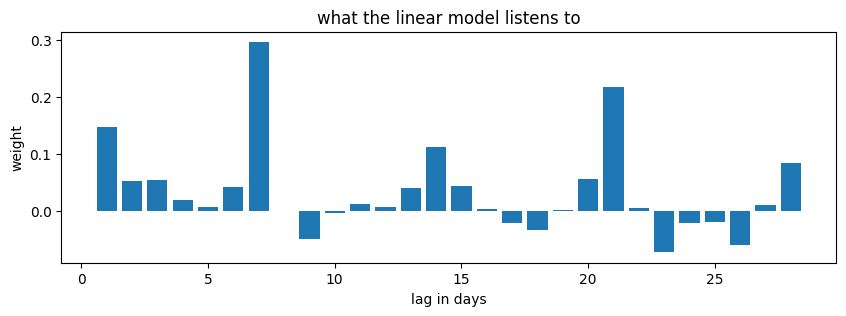

In [9]:
def fit_linear(Xtr, Ytr):
    A = np.c_[Xtr, np.ones(len(Xtr))]
    return np.linalg.lstsq(A, Ytr, rcond=None)[0]          # 28 weights + 1 bias (works for several answers too)
def predict_linear(w, X):
    return np.c_[X, np.ones(len(X))] @ w

a, b = FOLDS[0]
tr, te = masks(a, b)
w = fit_linear(X[tr], Y[tr])
print("parameters:", w.size, "(28 weights + 1 bias)")
lag_w = w[:-1][::-1]                    # lag_w[k-1] = weight on the value k days before the answer
print("weight on lag  1: %+.3f   lag  2: %+.3f   lag  3: %+.3f" % (lag_w[0], lag_w[1], lag_w[2]))
print("weight on lag  7: %+.3f   lag 14: %+.3f   lag 21: %+.3f   lag 28: %+.3f" % (lag_w[6], lag_w[13], lag_w[20], lag_w[27]))
print("all 28, lag 1 first:", np.round(lag_w, 2))
print("sum of the weights on lags 7, 14, 21 and 28: %.3f" % lag_w[[6, 13, 20, 27]].sum())
print("sum of all 28 weights: %.3f   bias: %.1f" % (lag_w.sum(), w[-1]))
print("block 1: MAE %.1f | seasonal naive %.1f" % (mae(Y[te], predict_linear(w, X[te])), scores["seasonal naive"][0]))

plt.figure(figsize=(10, 3)); plt.bar(range(1, 29), lag_w); plt.xlabel("lag in days"); plt.ylabel("weight")
plt.title("what the linear model listens to"); plt.show()

### Why we see this

The model has rediscovered the baselines and blended them. The large weights sit on lags 7, 14, 21 and 28
(the same weekday in each of the last four weeks: together 0.71) and on lag 1 (0.15: yesterday's mood
lingers). The rest are close to zero.

The 28 weights sum to 0.94 and the bias is about 14 loaves. Read that as a sentence: "the forecast is 94%
of a weighted average of the recent past, plus a small pull towards the old average". If the level of the
series jumps, this model follows 94% of the jump at once. Remember that number in Step 13.

In this first block the linear model is no better than the seasonal naive: 13.3 against 13.4.

---
## Step 10 - A small LSTM, and the cost of one fit

Chapter 20's layer, used as there: the window goes in as 28 steps of 1 feature, the last hidden state
(16 numbers) goes to one Dense unit. Networks want inputs of ordinary size, so we subtract a mean and
divide by a standard deviation, **both computed from the fitting days only**, and undo it on the forecast.

**Predict before you run:** an LSTM layer has 4 gates-worth of weights, each a Dense layer from (inputs +
units) to units. Count the parameters of `LSTM(16)` on 1 feature, then add the head.

In [10]:
def scaler(a):
    """Mean and standard deviation of the days before a: the only statistics a forecaster may use."""
    return float(y[:a].mean()), float(y[:a].std())

def build_lstm(outputs=1):
    return keras.Sequential([
        layers.Input(shape=(L, 1)),
        layers.LSTM(16),
        layers.Dense(outputs),
    ], name="lstm")

def fit_net(build, Xtr, Ytr, mu, sd, seed=SEED, epochs=30):
    keras.utils.set_random_seed(seed)
    m = build()
    m.compile(optimizer=keras.optimizers.Adam(5e-3), loss="mae")
    m.fit(((Xtr - mu) / sd)[..., None], (Ytr - mu) / sd, epochs=epochs, batch_size=64, verbose=0)
    return m
def predict_net(m, X, mu, sd):
    return m(((X - mu) / sd)[..., None].astype("float32"), training=False).numpy().squeeze(-1) * sd + mu

lstm = build_lstm()
by_hand = 4 * ((1 + 16) * 16 + 16) + (16 * 1 + 1)
print("LSTM(16) on 1 feature: 4 x ((1 + 16) x 16 + 16) = %d, head 16 + 1 = 17, total %d" % (4 * ((1 + 16) * 16 + 16), by_hand))
assert lstm.count_params() == by_hand == 1169

mu, sd = scaler(a)
t0 = time.time()
lstm = fit_net(build_lstm, X[tr], Y[tr], mu, sd)
print("one fit on %d pairs, 30 epochs: %.1f seconds" % (tr.sum(), time.time() - t0))
print("block 1: MAE %.1f | linear %.1f | seasonal naive %.1f" % (
    mae(Y[te], predict_net(lstm, X[te], mu, sd)), mae(Y[te], predict_linear(w, X[te])), scores["seasonal naive"][0]))

LSTM(16) on 1 feature: 4 x ((1 + 16) x 16 + 16) = 1152, head 16 + 1 = 17, total 1169


one fit on 1068 pairs, 30 epochs: 4.0 seconds
block 1: MAE 10.6 | linear 13.3 | seasonal naive 13.4


### Why we see this

1,169 parameters, forty times the linear model, fitted to about a thousand overlapping pairs. On this
first, quiet block the LSTM is the best forecaster so far. If the lab stopped here, with one exam window,
the conclusion would be "the LSTM wins". Keep that conclusion in mind for the next three steps.

---
## Step 11 - A small 1-D CNN

Chapter 15's dilated convolution, on a sequence: a first layer of 16 filters, each 7 days wide, then a
second layer of 16 filters of width 7 with a gap of 2 between the days it reads, then the average over
time and one Dense unit.

**Predict before you run:** how many days of history does one output of the second layer see? And how many
parameters does the model have?

In [11]:
def build_cnn():
    return keras.Sequential([
        layers.Input(shape=(L, 1)),
        layers.Conv1D(16, 7, activation="relu"),                     # sees 7 days
        layers.Conv1D(16, 7, dilation_rate=2, activation="relu"),    # sees 7 + 6 x 2 = 19 days
        layers.GlobalAveragePooling1D(),
        layers.Dense(1),
    ], name="cnn")

cnn = build_cnn()
c1, c2, head = 7 * 1 * 16 + 16, 7 * 16 * 16 + 16, 16 + 1
print("Conv1D(16, 7) on 1 channel:      7 x 1 x 16 + 16  = %d   output %s" % (c1, cnn.layers[0].output.shape))
print("Conv1D(16, 7, dilation 2) on 16: 7 x 16 x 16 + 16 = %d   output %s" % (c2, cnn.layers[1].output.shape))
print("Dense(1): %d   total %d" % (head, c1 + c2 + head))
assert cnn.count_params() == c1 + c2 + head == 1953
print("days seen by one output of the second layer: 7 + (7 - 1) x 2 =", 7 + 6 * 2)

Conv1D(16, 7) on 1 channel:      7 x 1 x 16 + 16  = 128   output (None, 22, 16)
Conv1D(16, 7, dilation 2) on 16: 7 x 16 x 16 + 16 = 1808   output (None, 10, 16)
Dense(1): 17   total 1953
days seen by one output of the second layer: 7 + (7 - 1) x 2 = 19


### Why we see this

The first layer shortens 28 steps to 22 (28 - 7 + 1), the second to 10 (22 - 12), and each of those 10
positions sees 19 days. The parameter count obeys Chapter 14's rule with one spatial axis instead of two:
kernel width times channels in, plus one, times channels out. Dilation widens the view without adding a
single weight.

---
## Step 12 - The exam: walk-forward validation of everything

Now the full procedure, for the linear model, the LSTM and the CNN: before each of the 4 blocks, refit on
all the pairs whose answer lies in the past, with a scaler from the past, then forecast the block one day
at a time. The networks are trained twice, with two different seeds, because one training run of a small
network is one draw from a lottery.

**Predict before you run:** write down the ranking you expect for the mean over the 4 blocks: seasonal
naive, linear, LSTM, CNN. Then say which block will be the hardest.

In [12]:
SEEDS = [SEED, SEED + 1]
preds = {}                               # preds[name] = forecasts for the 364 exam days, in order
nets = {}                                # nets[(name, block)] = (model, mu, sd), first seed only
t0 = time.time()
lin_m, lin_p = [], []
for k, (a, b) in enumerate(FOLDS):
    tr, te = masks(a, b)
    w_k = fit_linear(X[tr], Y[tr])
    lin_p.append(predict_linear(w_k, X[te])); lin_m.append(mae(Y[te], lin_p[-1]))
scores["linear, 28 lags"] = lin_m; preds["linear, 28 lags"] = np.concatenate(lin_p)
for name, build in [("LSTM", build_lstm), ("CNN", build_cnn)]:
    for seed in SEEDS:
        m_list, p_list = [], []
        for k, (a, b) in enumerate(FOLDS):
            tr, te = masks(a, b)
            mu, sd = scaler(a)
            net = fit_net(build, X[tr], Y[tr], mu, sd, seed=seed)
            p_list.append(predict_net(net, X[te], mu, sd)); m_list.append(mae(Y[te], p_list[-1]))
            if seed == SEEDS[0]:
                nets[(name, k)] = (net, mu, sd)
        key = "%s, seed %d" % (name, seed)
        scores[key] = m_list; preds[key] = np.concatenate(p_list)
print("16 network fits and 4 linear fits in %.0f seconds\n" % (time.time() - t0))

exam = T >= EXAM0
for name, f in BASELINES.items():
    preds[name] = f(X[exam])
scale_k = [naive_scale(a) for a, _ in FOLDS]
PARAMS = {"linear, 28 lags": 29, "LSTM": 1169, "CNN": 1953, "linear + calendar": 59}
def table(names):
    """MAE per block, the mean, MASE, and the mean MAE divided by the seasonal naive's on the same days."""
    naive = np.mean(scores["seasonal naive"])
    print("MAE in each block        params      1       2       3       4     mean    MASE   vs naive")
    for name in names:
        m = scores[name]; p = PARAMS.get(name.split(", seed")[0], 0)
        print("%-22s %6s  %6.1f  %6.1f  %6.1f  %6.1f  %6.2f  %6.2f  %6.2f" % (
            name, p if p else "-", *m, np.mean(m), np.mean(np.array(m) / scale_k), np.mean(m) / naive))
table(list(scores))

16 network fits and 4 linear fits in 60 seconds

MAE in each block        params      1       2       3       4     mean    MASE   vs naive
last value                  -    20.1    23.2    24.9    28.4   24.15    1.73    1.48
seasonal naive              -    13.4    18.6    16.1    17.1   16.31    1.17    1.00
moving average              -    19.6    23.6    22.7    26.6   23.14    1.66    1.42
weekday mean                -    14.7    19.3    15.5    15.1   16.12    1.16    0.99
linear, 28 lags            29    13.3    16.2    14.9    15.3   14.92    1.07    0.91
LSTM, seed 55            1169    10.6    32.5    18.0    15.4   19.10    1.37    1.17
LSTM, seed 56            1169     9.8    32.9    18.8    15.2   19.17    1.38    1.18
CNN, seed 55             1953    12.9    17.6    18.3    16.7   16.38    1.17    1.00
CNN, seed 56             1953    14.8    19.4    15.0    15.6   16.20    1.16    0.99


### Why we see this

Read the table by columns first. In block 1 both LSTMs are clearly the best forecasters. In block 2,
where the level shifts, they are clearly the worst, behind every baseline, while the linear model and the
seasonal naive take the shift in their stride. In blocks 3 and 4 the LSTM is level with the linear model
or behind it. Averaged over the year, **the model with 29 parameters is first, 9% ahead of "same as last
week"; the CNN is level with "same as last week"; and the LSTM finishes 17% behind it**.

The seeds matter too. The two LSTMs agree closely, but the two CNNs differ by more than 3 loaves in block
3, which is more than the gap between the CNN and the linear model. A difference between two networks that
is smaller than the difference between two seeds of one network means nothing.

Had the exam been block 1 alone, the report would have said "the LSTM cuts the error by a fifth". This is
one invented series, built to be the hard case for a deep model: one short history and a world that changes
once. It is also the case most people meet first.

---
## Step 13 - Why the LSTM lost block 2

A score says who lost. It does not say why. Look at the forecasts either side of the shift.

**Predict before you run:** after day 1,215 the sales are about 35 loaves higher than anything the models
were fitted on. What is the largest value an LSTM can forecast, and why might there be one?

block 2 (days 1187 to 1277), fitted on days before 1187
                      MAE before the shift   MAE after the shift   mean error after (forecast - answer)
  seasonal naive            21.4                  17.4                  -4.4
  linear, 28 lags           16.8                  15.9                 -10.4
  LSTM                      14.4                  40.5                 -37.3
  CNN                       16.8                  18.0                  +5.0

largest answer in the fitting data: 323 | largest answer in block 2: 368
largest forecast in block 2:  linear 353 | LSTM 310 | CNN 371
the 10 busiest days of block 2: mean answer 355 | linear 328 | LSTM 296 | CNN 345


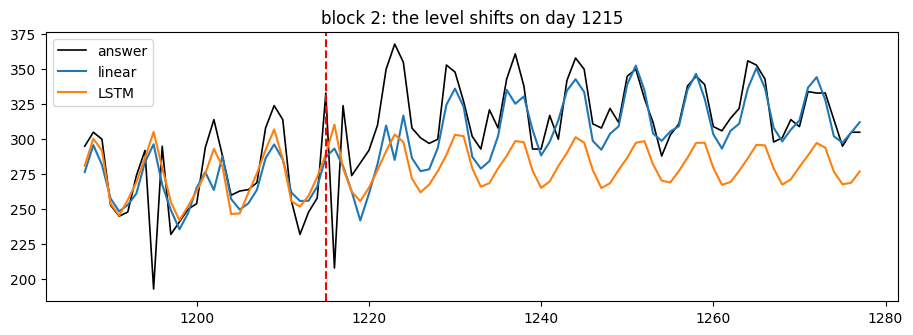

In [13]:
k = 1; a, b = FOLDS[k]
tr, te = masks(a, b)
before = te & (T < SHIFT_DAY); after = te & (T >= SHIFT_DAY)
net, mu, sd = nets[("LSTM", k)]
cnn_net, _, _ = nets[("CNN", k)]
p_lstm = predict_net(net, X, mu, sd); p_cnn = predict_net(cnn_net, X, mu, sd)
w_k = fit_linear(X[tr], Y[tr]); p_lin = predict_linear(w_k, X)
print("block 2 (days %d to %d), fitted on days before %d" % (a, b - 1, a))
print("                      MAE before the shift   MAE after the shift   mean error after (forecast - answer)")
for name, p in [("seasonal naive", X[:, -7]), ("linear, 28 lags", p_lin), ("LSTM", p_lstm), ("CNN", p_cnn)]:
    print("  %-16s        %6.1f                %6.1f                %+6.1f" % (name, mae(Y[before], p[before]), mae(Y[after], p[after]), float(np.mean(p[after] - Y[after]))))
print("\nlargest answer in the fitting data: %d | largest answer in block 2: %d" % (Y[tr].max(), Y[te].max()))
print("largest forecast in block 2:  linear %.0f | LSTM %.0f | CNN %.0f" % (p_lin[te].max(), p_lstm[te].max(), p_cnn[te].max()))
top = np.argsort(Y[te])[-10:]
print("the 10 busiest days of block 2: mean answer %.0f | linear %.0f | LSTM %.0f | CNN %.0f" % (
    Y[te][top].mean(), p_lin[te][top].mean(), p_lstm[te][top].mean(), p_cnn[te][top].mean()))

plt.figure(figsize=(11, 3.5))
plt.plot(T[te], Y[te], "k", lw=1.2, label="answer"); plt.plot(T[te], p_lin[te], label="linear"); plt.plot(T[te], p_lstm[te], label="LSTM")
plt.axvline(SHIFT_DAY, color="r", ls="--"); plt.legend(); plt.title("block 2: the level shifts on day 1215"); plt.show()

### Why we see this

Before the shift all the models are in their usual order. After it, the LSTM's forecasts sit far below
the answers and stay there for the rest of the block. The reason is in the cell's arithmetic (Chapter 20):
its hidden state passes through `tanh`, so each of the 16 numbers the head receives lies between -1 and 1.
The head can therefore never output more than its bias plus the sum of its weights' sizes. The network
learnt to reach the largest values in its fitting data and has no way to reach beyond them: it
**saturates**. A linear model has no such ceiling (double the inputs and the forecast doubles), and the
seasonal naive copies whatever happened, however strange.

The linear model is not perfect here either. It runs about 10 loaves low after the shift, because its
weights sum to 0.94 and the remaining 6% pulls towards an average that is now out of date. The seasonal
naive, with a single weight of exactly 1, is low by less. The CNN, made of straight-line pieces (ReLU),
extrapolates as a linear model does.

The cure is not a bigger LSTM. It is to give the network a quantity that stays in a familiar range:
forecast the change from last week instead of the level, or scale each window by its own mean. Exercise 1
asks you to try it.

---
## Step 14 - Where the error lives

Now leave block 2 out and look at the three ordinary blocks. Before changing any model, find out which
days the error comes from. A public holiday is a day none of these models was told about, and it leaves a
dent in the window for the next 28 days.

**Predict before you run:** split the exam days of blocks 1, 3 and 4 into "the day itself is a holiday or
closed day", "a special day somewhere in the window" and "no special day in sight". How different are the
three groups? Does the LSTM's lead in block 1 show up as a lead in any group?

In [14]:
special = S["holiday"] | S["closed"]
in_window = np.array([special[i:i + L].any() for i in range(len(T))])      # a special day among the 28 inputs
today = special[T]
quiet = exam & ((T < FOLDS[1][0]) | (T >= FOLDS[2][0]))                    # blocks 1, 3 and 4
ex = np.where(exam)[0]
def exam_mae(name, mask):
    return mae(Y[mask], preds[name][np.isin(ex, np.where(mask)[0])])
groups = [("the day itself is special", quiet & today),
          ("a special day in the window", quiet & in_window & ~today),
          ("no special day in sight", quiet & ~in_window & ~today)]
LSTM1, CNN1 = "LSTM, seed %d" % SEED, "CNN, seed %d" % SEED
print("blocks 1, 3 and 4                days   seasonal naive   linear    LSTM     CNN")
for label, mask in groups:
    print("  %-28s %4d      %6.1f       %6.1f  %6.1f  %6.1f" % (label, mask.sum(), exam_mae("seasonal naive", mask),
          exam_mae("linear, 28 lags", mask), exam_mae(LSTM1, mask), exam_mae(CNN1, mask)))
tot = exam_mae("linear, 28 lags", quiet) * quiet.sum()
part = exam_mae("linear, 28 lags", groups[0][1]) * groups[0][1].sum()
print("\nlinear model: the %d special days are %.1f%% of the days and %.0f%% of the total error" % (
    groups[0][1].sum(), 100 * groups[0][1].sum() / quiet.sum(), 100 * part / tot))

blocks 1, 3 and 4                days   seasonal naive   linear    LSTM     CNN
  the day itself is special       5       153.6        153.2   154.5   157.2
  a special day in the window   146        14.3         14.2    14.2    14.1
  no special day in sight       122        11.3          9.1     9.5    12.4

linear model: the 5 special days are 1.8% of the days and 19% of the total error


### Why we see this

On the holiday itself nobody is right: each model misses by about 150 loaves, most of a day's sales. Five
days out of 273 carry about a fifth of the linear model's whole error. In the four weeks that follow, the
dent sits in the window: the linear model multiplies it by a weight and forecasts too low, and the
seasonal naive copies it outright a week later. On those days every model is about 14 loaves out. Only
with no special day in sight do the models show what they can do, and there the linear model is the best
of them, ahead of the LSTM.

So the LSTM's lead in block 1 does not survive as a general advantage: pooled over three ordinary blocks
it is level with the linear model or behind it in every group. And the table says plainly where the next
improvement is to be had. It is not in the architecture. It is in telling the model about the calendar.

---
## Step 15 - A covariate known in advance: the calendar

Some things about the future are known today: the weekday, the public holidays, the day the shop will be
closed. A forecaster may use those for the day it is forecasting. We give the linear model three kinds of
extra column: "is the forecast day a public holiday", "is the forecast day a closed day", and 28 flags
saying which days of the window were special. All of it is printed on a calendar months ahead.

**Predict before you run:** how much of the linear model's error is the calendar's fault?

In [15]:
flag_window = np.stack([special[i:i + L] for i in range(len(T))]).astype(float)        # (1432, 28)
X_cal = np.c_[X, flag_window, S["holiday"][T].astype(float), S["closed"][T].astype(float)]
print("columns: 28 lags + 28 window flags + 2 flags for the forecast day =", X_cal.shape[1], "| parameters:", X_cal.shape[1] + 1)
cal_m, cal_p = [], []
for a, b in FOLDS:
    tr, te = masks(a, b)
    w_c = fit_linear(X_cal[tr], Y[tr])
    cal_p.append(predict_linear(w_c, X_cal[te])); cal_m.append(mae(Y[te], cal_p[-1]))
scores["linear + calendar"] = cal_m; preds["linear + calendar"] = np.concatenate(cal_p)
print()
table(["seasonal naive", "linear, 28 lags", "linear + calendar", LSTM1, CNN1])
print("\nsame three groups as Step 14 (blocks 1, 3 and 4), linear + calendar:")
for label, mask in groups:
    print("  %-28s %6.1f" % (label, exam_mae("linear + calendar", mask)))

columns: 28 lags + 28 window flags + 2 flags for the forecast day = 58 | parameters: 59

MAE in each block        params      1       2       3       4     mean    MASE   vs naive
seasonal naive              -    13.4    18.6    16.1    17.1   16.31    1.17    1.00
linear, 28 lags            29    13.3    16.2    14.9    15.3   14.92    1.07    0.91
linear + calendar          59     9.2    10.5     9.7    10.4    9.96    0.71    0.61
LSTM, seed 55            1169    10.6    32.5    18.0    15.4   19.10    1.37    1.17
CNN, seed 55             1953    12.9    17.6    18.3    16.7   16.38    1.17    1.00

same three groups as Step 14 (blocks 1, 3 and 4), linear + calendar:
  the day itself is special      38.7
  a special day in the window     9.9
  no special day in sight         8.4


### Why we see this

One honest piece of information about the future is worth more than any change of architecture in this
lab. The error falls by a third, from 14.9 to 10.0 loaves, and the MASE drops to 0.71: well below 1 by any
reading. The linear model with a calendar is the best forecaster in every block, including block 1, which
the LSTM used to win. The lesson is about where to spend effort: before making the model cleverer, ask
what is already known about the day being forecast.

The rule that keeps this honest: a covariate may be used for the forecast day only if its value is known
when the forecast is made. The calendar is. Tomorrow's weather is known only as a forecast. Tomorrow's
footfall is not known at all, and Step 20 shows what happens when a column of that kind slips in.

---
## Step 16 - Further ahead: 1, 7 and 28 days, recursive against direct

A baker orders flour for the month, so a forecast for tomorrow is not enough. There are two ways to look
28 days ahead with the tools we have.

* **Recursive**: forecast tomorrow, append the forecast to the window as if it were real, forecast the day
  after, and repeat 28 times. One model, used again and again on its own output.
* **Direct**: fit a separate answer for each horizon. For the linear model that is 28 sets of weights; for
  the LSTM it is a head with 28 outputs instead of 1.

The baseline also changes: 28 days ahead, "same weekday last week" has to mean the last same weekday that
has actually been observed.

**Predict before you run:** how much worse is a 28-day forecast than a 1-day forecast? And which is
better at 28 days, recursive or direct?

Xp

 (1405, 28) | Yp (1405, 28) | direct LSTM head: 16 x 28 + 28 = 476 so 1628 parameters


origins per block: 64, in all 256 | 32 seconds

MAE by horizon            1 day   7 days  14 days  28 days   mean of 1..28
seasonal naive            17.0     16.9     18.4     22.5     19.4
linear, recursive         15.6     17.0     18.3     22.5     19.3
linear, direct            15.7     16.6     17.8     21.9     18.8
LSTM, recursive           17.8     19.9     23.9     30.7     24.6
LSTM, direct              19.1     18.5     19.7     21.7     21.9

weekly swing of the path (standard deviation within a week)   week 1   week 4
  the answers                                                  25.1     26.1
  seasonal naive                                               25.9     25.9
  linear, recursive                                            19.3     17.2
  linear, direct                                               19.4     18.8
  LSTM, recursive                                              19.6     20.2
  LSTM, direct                                                 18.9     19.1


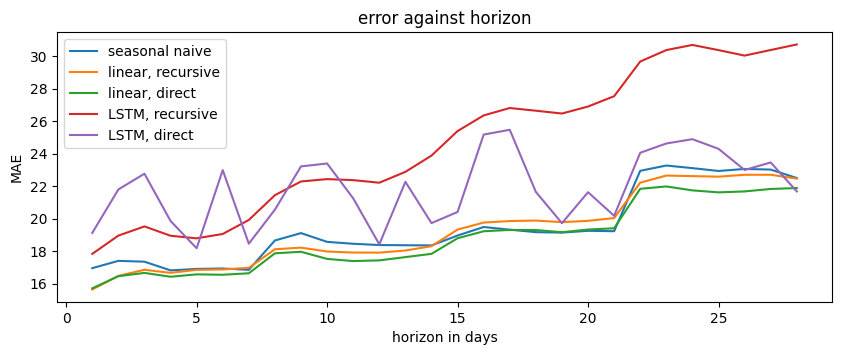

In [16]:
H = 28
def make_paths(series, L, H):
    """Xp[i] = series[i : i+L]; Yp[i] = the next H values; O[i] = day index of the first of them (the origin)."""
    n = len(series) - L - H + 1
    Xp = np.stack([series[i:i + L] for i in range(n)])
    Yp = np.stack([series[i + L:i + L + H] for i in range(n)])
    return Xp, Yp, np.arange(n) + L

Xp, Yp, O = make_paths(y, L, H)
print("Xp", Xp.shape, "| Yp", Yp.shape, "| direct LSTM head: 16 x 28 + 28 =", 16 * 28 + 28, "so", 1152 + 16 * 28 + 28, "parameters")

def recursive(step_fn, X0, H):
    """Roll a one-step forecaster forward H times, feeding each forecast back in as the newest input."""
    win = X0.copy(); out = []
    for _ in range(H):
        f = step_fn(win); out.append(f)
        win = np.c_[win[:, 1:], f]
    return np.stack(out, axis=1)

def seasonal_naive_path(X0, H):
    return np.stack([X0[:, -7 + (h % 7)] for h in range(H)], axis=1)       # the last observed same weekday

paths = {n: [] for n in ["seasonal naive", "linear, recursive", "linear, direct", "LSTM, recursive", "LSTM, direct"]}
truth = []
t0 = time.time()
for k, (a, b) in enumerate(FOLDS):
    fit = O + H - 1 < a                       # every one of the 28 answers lies in the past
    ex_o = (O >= a) & (O + H - 1 < b)         # every one of the 28 answers lies inside the block
    truth.append(Yp[ex_o])
    paths["seasonal naive"].append(seasonal_naive_path(Xp[ex_o], H))
    w1 = fit_linear(X[T < a], Y[T < a])
    paths["linear, recursive"].append(recursive(lambda win: predict_linear(w1, win), Xp[ex_o], H))
    paths["linear, direct"].append(predict_linear(fit_linear(Xp[fit], Yp[fit]), Xp[ex_o]))
    net, mu, sd = nets[("LSTM", k)]
    paths["LSTM, recursive"].append(recursive(lambda win: predict_net(net, win, mu, sd), Xp[ex_o], H))
    keras.utils.set_random_seed(SEED)
    direct = build_lstm(outputs=H)
    if k == 0:
        assert direct.count_params() == 1152 + 16 * 28 + 28 == 1628
    direct.compile(optimizer=keras.optimizers.Adam(5e-3), loss="mae")
    direct.fit(((Xp[fit] - mu) / sd)[..., None], (Yp[fit] - mu) / sd, epochs=30, batch_size=64, verbose=0)
    paths["LSTM, direct"].append(direct(((Xp[ex_o] - mu) / sd)[..., None].astype("float32"), training=False).numpy() * sd + mu)
truth = np.concatenate(truth); paths = {n: np.concatenate(p) for n, p in paths.items()}
print("origins per block: %d, in all %d | %.0f seconds\n" % (ex_o.sum(), len(truth), time.time() - t0))

err = {n: np.abs(p - truth).mean(axis=0) for n, p in paths.items()}       # MAE at each horizon 1..28
print("MAE by horizon            1 day   7 days  14 days  28 days   mean of 1..28")
for n, e in err.items():
    print("%-22s  %6.1f   %6.1f   %6.1f   %6.1f   %6.1f" % (n, e[0], e[6], e[13], e[27], e.mean()))
swing = lambda p, wk: float(p[:, 7 * wk:7 * wk + 7].std(axis=1).mean())    # how much a path moves within one week
print("\nweekly swing of the path (standard deviation within a week)   week 1   week 4")
print("  %-22s                                      %5.1f    %5.1f" % ("the answers", swing(truth, 0), swing(truth, 3)))
for n, p in paths.items():
    print("  %-22s                                      %5.1f    %5.1f" % (n, swing(p, 0), swing(p, 3)))

plt.figure(figsize=(10, 3.5))
for n, e in err.items():
    plt.plot(range(1, H + 1), e, label=n)
plt.xlabel("horizon in days"); plt.ylabel("MAE"); plt.legend(); plt.title("error against horizon"); plt.show()

### Why we see this

(The 1-day column differs a little from Step 12 because only origins with all 28 answers inside the block
are used: 64 per block instead of 91.)

Four things to take from the table.

The error grows with the horizon for every method: about 16 loaves a day ahead, about 22 a month ahead.
For the good methods it grows slowly, because most of what is predictable here is the weekly rhythm, and
that is as predictable in four weeks as it is tomorrow.

The seasonal naive stays hard to beat at every horizon. A month ahead it is level with the recursive
linear model, and the best method beats it by under a loaf.

**Recursive forecasts compound their errors.** The recursive LSTM is the worst method at every horizon
beyond the first day and falls further behind as it goes: from 17.8 to 30.7. It was trained to look one
day ahead from real values and is then asked to trust its own output 27 times; each small error becomes an
input. The direct LSTM, with one output per horizon and no feedback, is nine loaves better at 28 days, and
at that range it is the best method in the table by a whisker. For the linear model the two routes are
close, with direct ahead by about half a loaf.

The last block of numbers shows a quieter effect. Every forecast swings less within a week than the
answers do, which is right: a forecast should not try to reproduce the noise. But the recursive linear
path loses a further tenth of its swing between week 1 and week 4, while the direct one nearly holds. A
recursive forecaster fed on its own smooth output slides, slowly, towards an average.

---
## Step 17 - A forecast is a range

"217 loaves" is a point. A baker needs to know how wrong it might be. The cheapest honest range comes from
the model's own past errors: take the errors on the fitting data, find the values that 10% and 90% of them
fall below, and add those two numbers to each forecast. That claims to be an **80% interval**: the answer
should fall inside it four times in five. A claim like that can be checked.

**Predict before you run:** will the interval cover 80% of the answers in every block?

In [17]:
print("linear + calendar, 80% interval from the errors on the fitting data")
print("block   lower    upper    width    answers inside (claimed: 80%)")
inside_all = []
for k, (a, b) in enumerate(FOLDS):
    tr, te = masks(a, b)
    w_c = fit_linear(X_cal[tr], Y[tr])
    resid = Y[tr] - predict_linear(w_c, X_cal[tr])
    lo, hi = np.quantile(resid, [0.10, 0.90])
    f = predict_linear(w_c, X_cal[te])
    inside = (Y[te] >= f + lo) & (Y[te] <= f + hi); inside_all.append(inside)
    print("  %d     %+6.1f   %+6.1f   %5.1f    %5.1f%%" % (k + 1, lo, hi, hi - lo, 100 * inside.mean()))
print("all four blocks: %.1f%%" % (100 * np.concatenate(inside_all).mean()))

def pinball(a, f, q):
    """The quantile loss of Chapter 6: misses above the forecast cost q, misses below cost 1 - q."""
    e = a - f
    return float(np.mean(np.maximum(q * e, (q - 1) * e)))
tr, te = masks(*FOLDS[0]); w_c = fit_linear(X_cal[tr], Y[tr]); f = predict_linear(w_c, X_cal[te])
lo, hi = np.quantile(Y[tr] - predict_linear(w_c, X_cal[tr]), [0.10, 0.90])
print("\nblock 1, pinball loss of the 90%% line: %.2f | of the point forecast used as a 90%% line: %.2f" % (
    pinball(Y[te], f + hi, 0.9), pinball(Y[te], f, 0.9)))

linear + calendar, 80% interval from the errors on the fitting data
block   lower    upper    width    answers inside (claimed: 80%)
  1      -12.0    +11.8    23.8     65.9%
  2      -11.9    +12.2    24.1     70.3%
  3      -12.5    +12.6    25.1     74.7%
  4      -12.1    +12.7    24.8     75.8%
all four blocks: 71.7%

block 1, pinball loss of the 90% line: 2.11 | of the point forecast used as a 90% line: 5.38


### Why we see this

The interval claims 80% and delivers about 72%: between 66% and 76% depending on the block. It is too
narrow everywhere. Two reasons. Errors on the data a model was fitted to are smaller than its errors on
new days, so a range built from them is optimistic: the honest source is the errors of forecasts made
for days the model had not seen (Exercise 3). And the exam year is harder than the past, as the seasonal
naive's own error already showed in Step 7. An interval is a claim about the future, and like the forecast
itself it has to be scored on days it has not seen. Chapter 63 takes this further.

The last line scores a single quantile with the pinball loss of Chapter 6: a line meant to sit above 90%
of the answers is charged little when it is above the answer and a lot when it is below.

---
## Step 18 - Crime 1: shuffle, then split

Now the leaks, committed on purpose. For each one we report two numbers: the score the criminal would
**claim**, and the score the same recipe earns in an **honest** exam (fit on the first three years, test
on the fourth, 364 days, no refitting).

The first crime is the most common line of code in machine learning: shuffle the pairs and hold out a
random quarter. We hold out exactly 364 random pairs so that the two exams are the same size.

**Predict before you run:** which model will the shuffle flatter more, the linear model or the LSTM? Why?

In [18]:
HONEST_TR, HONEST_TE = T < EXAM0, T >= EXAM0
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(T))
SH_TE = np.zeros(len(T), bool); SH_TE[perm[:364]] = True
SH_TR = ~SH_TE
near = np.mean([np.any(SH_TR[max(0, i - 3):i + 4]) for i in np.where(SH_TE)[0]])
print("shuffled split: %d pairs to fit, %d held out" % (SH_TR.sum(), SH_TE.sum()))
print("held-out answers with a fitting answer within 3 days: %.0f%%" % (100 * near))
print("held-out answers that also appear as an INPUT of some fitting pair: %.0f%%" % (
    100 * np.mean([np.any(SH_TR[i + 1:i + L + 1]) for i in np.where(SH_TE)[0]])))

crimes = []                              # (crime, model, claimed MAE, honest MAE)
t0 = time.time()
w_sh = fit_linear(X[SH_TR], Y[SH_TR]); w_ho = fit_linear(X[HONEST_TR], Y[HONEST_TR])
crimes.append(("shuffled split", "linear", mae(Y[SH_TE], predict_linear(w_sh, X[SH_TE])), mae(Y[HONEST_TE], predict_linear(w_ho, X[HONEST_TE]))))
mu_h, sd_h = scaler(EXAM0)
mu_all, sd_all = float(y.mean()), float(y.std())
lstm_sh = fit_net(build_lstm, X[SH_TR], Y[SH_TR], mu_all, sd_all)      # the shuffler scales with everything, too
lstm_ho = fit_net(build_lstm, X[HONEST_TR], Y[HONEST_TR], mu_h, sd_h)
honest_lstm = mae(Y[HONEST_TE], predict_net(lstm_ho, X[HONEST_TE], mu_h, sd_h))
crimes.append(("shuffled split", "LSTM", mae(Y[SH_TE], predict_net(lstm_sh, X[SH_TE], mu_all, sd_all)), honest_lstm))
print("(%.0f seconds)\n" % (time.time() - t0))
sn = mae(Y[HONEST_TE], X[HONEST_TE][:, -7]); sn_sh = mae(Y[SH_TE], X[SH_TE][:, -7])
print("crime             model     claimed MAE   honest MAE   too good by   vs naive: claimed   honest")
for c, m, claimed, honest in crimes:
    print("%-16s  %-7s   %8.1f     %8.1f       %4.0f%%              %.2f         %.2f" % (
        c, m, claimed, honest, 100 * (honest - claimed) / honest, claimed / sn_sh, honest / sn))
print("\nseasonal naive on the shuffled hold-out: %.1f | on the honest exam: %.1f" % (sn_sh, sn))

shuffled split: 1068 pairs to fit, 364 held out
held-out answers with a fitting answer within 3 days: 100%
held-out answers that also appear as an INPUT of some fitting pair: 100%


(11 seconds)

crime             model     claimed MAE   honest MAE   too good by   vs naive: claimed   honest
shuffled split    linear        12.8         15.0         15%              0.91         0.92
shuffled split    LSTM          12.3         24.2         49%              0.87         1.48

seasonal naive on the shuffled hold-out: 14.1 | on the honest exam: 16.3


### Why we see this

After a shuffle, the held-out days are scattered through all four years, and every one of them has
fitting days on both sides. The model is then asked to fill gaps in a history it has seen, which is
interpolation, when the real job is to step off the end of the history, which is extrapolation. Every
regime in the hold-out, including the months after the level shift, is also in the fitting data.

Be careful what you charge to the leak. Part of the gap between the two columns is that the last year is
a harder exam than a random sample of all four: the seasonal naive, which learns nothing and so cannot be
flattered, also scores better on the shuffled days (14.1 against 16.3). The last two columns remove that
by dividing by the naive on the same days. For the linear model the ratio hardly moves (0.91 and 0.92):
the shuffle did not flatter it at all. For the LSTM it moves from 0.87 to 1.48.

That asymmetry is the dangerous part. A model with 29 numbers behaves much the same inside and outside
its experience. A network that saturates outside it looks excellent on the shuffled exam, where nothing
is outside. **A leak does not only inflate scores. It inflates the scores of flexible models most, and so
it changes which model you choose.** On the shuffled exam the LSTM is the best of the three; on the honest
one it is the worst.

(The honest column here is worse than Step 12's for a second reason: no refitting for a whole year. That
is drift, and it is the subject of Chapter 61.)

---
## Step 19 - Crime 2: scaling with statistics from the whole series

The second crime looks like tidiness: compute the mean and standard deviation once, on the whole series,
before splitting. The scaler has then seen the future level of the series, including the shift.

**Predict before you run:** will this change the linear model's forecasts at all? Will it help the LSTM?

In [19]:
print("scaler from the fitting days only: mean %.1f, sd %.1f" % (mu_h, sd_h))
print("scaler from the whole series:      mean %.1f, sd %.1f" % (mu_all, sd_all))
zs = lambda v, mu, sd: (v - mu) / sd
w_a = fit_linear(zs(X[HONEST_TR], mu_h, sd_h), zs(Y[HONEST_TR], mu_h, sd_h))
w_b = fit_linear(zs(X[HONEST_TR], mu_all, sd_all), zs(Y[HONEST_TR], mu_all, sd_all))
p_a = predict_linear(w_a, zs(X[HONEST_TE], mu_h, sd_h)) * sd_h + mu_h
p_b = predict_linear(w_b, zs(X[HONEST_TE], mu_all, sd_all)) * sd_all + mu_all
print("linear model: largest difference between the two sets of forecasts: %.2e loaves" % np.max(np.abs(p_a - p_b)))
crimes.append(("whole-series scaler", "linear", mae(Y[HONEST_TE], p_b), mae(Y[HONEST_TE], p_a)))

t0 = time.time()
runs = {"honest": [honest_lstm], "leaky": []}
for seed in SEEDS:
    if seed != SEEDS[0]:
        m_ = fit_net(build_lstm, X[HONEST_TR], Y[HONEST_TR], mu_h, sd_h, seed=seed)
        runs["honest"].append(mae(Y[HONEST_TE], predict_net(m_, X[HONEST_TE], mu_h, sd_h)))
    m_ = fit_net(build_lstm, X[HONEST_TR], Y[HONEST_TR], mu_all, sd_all, seed=seed)
    runs["leaky"].append(mae(Y[HONEST_TE], predict_net(m_, X[HONEST_TE], mu_all, sd_all)))
print("LSTM, scaler from the fitting days:  MAE per seed", np.round(runs["honest"], 1), "mean %.1f" % np.mean(runs["honest"]))
print("LSTM, scaler from the whole series:  MAE per seed", np.round(runs["leaky"], 1), "mean %.1f" % np.mean(runs["leaky"]))
crimes.append(("whole-series scaler", "LSTM", float(np.mean(runs["leaky"])), float(np.mean(runs["honest"]))))
print("(%.0f seconds)" % (time.time() - t0))
print("largest scaled input the LSTM met while fitting: %.2f (honest) and %.2f (leaky)" % (
    zs(X[HONEST_TR], mu_h, sd_h).max(), zs(X[HONEST_TR], mu_all, sd_all).max()))
print("largest scaled input in the exam year:           %.2f (honest) and %.2f (leaky)" % (
    zs(X[HONEST_TE], mu_h, sd_h).max(), zs(X[HONEST_TE], mu_all, sd_all).max()))

scaler from the fitting days only: mean 235.7, sd 37.4
scaler from the whole series:      mean 248.3, sd 44.3
linear model: largest difference between the two sets of forecasts: 1.14e-13 loaves


LSTM, scaler from the fitting days:  MAE per seed [24.2 23. ] mean 23.6
LSTM, scaler from the whole series:  MAE per seed [23.4 22.4] mean 22.9
(15 seconds)
largest scaled input the LSTM met while fitting: 2.33 (honest) and 1.69 (leaky)
largest scaled input in the exam year:           3.70 (honest) and 2.84 (leaky)


### Why we see this

For the linear model the crime has no effect whatever: the two sets of forecasts agree to about thirteen
decimal places. Least squares gives the same forecasts under any shift and rescaling of its inputs, so
there is nothing for the leak to act on.

For the LSTM the leaky scaler is better by about 3% with both seeds. The direction makes sense: the leaky
scaler knows the series will climb, so the exam year's values look less extreme to the network (2.84
standard deviations at most, against 3.70) and it saturates a little later. But the gain is smaller than
the difference between two seeds of the same recipe. You would not detect this leak from the score, and
it would not change a decision.

So this leak is small **here**, and it is worth knowing why. A mean and a standard deviation of a long
series are two numbers that the future moves only a little. The same crime is serious when the statistic
is sharper: a minimum and maximum (the scaler then knows the highest value the future will reach), a
per-feature mean in a short series, a gap filled with a mean that includes later values, or target
encoding. The rule costs nothing to follow, so follow it: **fit every preprocessing step on the fitting
days only**, as if the exam days did not exist yet.

---
## Step 20 - Crime 3: a feature that contains the answer

The third crime arrives through a helpful-looking column. Someone adds "the 7-day average of sales" to
the inputs, computed with a library call whose window **ends on the day being forecast**. A second
version uses a centred window, three days either side. A third, correct, version ends the day before.

**Predict before you run:** the model already has the last 28 values. What can it do with a 7-day average
that includes the answer?

In [20]:
def rolling_mean_ending_at(day_index, width=7):
    return np.array([y[d - width + 1:d + 1].mean() for d in day_index])
ok = T <= N - 4                                    # the centred window needs 3 days after the answer
feat_incl = rolling_mean_ending_at(T)                               # days T-6 .. T      (contains the answer)
feat_cent = np.array([y[d - 3:d + 4].mean() if d <= N - 4 else np.nan for d in T])   # days T-3 .. T+3  (answer + future)
feat_prev = rolling_mean_ending_at(T - 1)                           # days T-7 .. T-1    (legal)

honest_lin = mae(Y[HONEST_TE & ok], predict_linear(w_ho, X[HONEST_TE & ok]))
print("linear on 28 lags, honest exam: MAE %.2f\n" % honest_lin)
print("extra column                              MAE on the exam year")
for label, feat in [("7-day mean ending the day before", feat_prev), ("7-day mean ending ON the forecast day", feat_incl),
                    ("7-day mean centred on the forecast day", feat_cent)]:
    Xf = np.c_[X, feat]
    w_f = fit_linear(Xf[HONEST_TR & ok], Y[HONEST_TR & ok])
    m_f = mae(Y[HONEST_TE & ok], predict_linear(w_f, Xf[HONEST_TE & ok]))
    print("  %-40s %8.4f" % (label, m_f))
    if "ON" in label:
        crimes.append(("answer in a feature", "linear", m_f, honest_lin))
        lw = w_f[:-1]
        print("     weight on the new column: %.3f | weights on lags 1 to 6: %s" % (lw[-1], np.round(lw[L - 6:L][::-1], 3)))
    if "centred" in label:
        crimes.append(("centred window", "linear", m_f, honest_lin))

linear on 28 lags, honest exam: MAE 15.12

extra column                              MAE on the exam year
  7-day mean ending the day before          15.1241
  7-day mean ending ON the forecast day      0.0000
     weight on the new column: 7.000 | weights on lags 1 to 6: [-1. -1. -1. -1. -1. -1.]
  7-day mean centred on the forecast day    12.3086


### Why we see this

The model has learnt subtraction. Seven times the 7-day average is the sum of seven days; six of those
days are already among the lags; take them away and what is left is the answer. The weights printed above
say exactly that: 7 on the new column, -1 on each of lags 1 to 6. The error is zero to four decimal
places, and the model is useless, because on the day you need the forecast the column cannot be computed.

The centred window is the same crime in a milder form: the answer is in it, mixed with three future days
the model cannot remove, so the error falls a long way without reaching zero. That version is the
dangerous one. A score of zero makes everyone suspicious. A score that is merely excellent gets shipped.

The legal version, ending the day before, changes nothing at all: it is a sum of values the model already
had. **A feature can only help if it carries information the inputs lack, and if that information is the
future, it is a leak.** For every column ask: at the moment the forecast is made, could this number have
been written down?

---
## Step 21 - The charge sheet

**Predict before you run:** which of the crimes was the most flattering? Which was the hardest to spot
from the score alone?

In [21]:
print("crime                  model     claimed MAE   honest MAE   the claim is too good by")
for c, m, claimed, honest in crimes:
    print("%-21s  %-7s   %8.2f     %8.2f       %5.1f%%" % (c, m, claimed, honest, 100 * (honest - claimed) / honest))
print("\nfor scale, the honest exam year: seasonal naive %.1f | linear on 28 lags %.1f" % (sn, mae(Y[HONEST_TE], predict_linear(w_ho, X[HONEST_TE]))))

print("\nthe year's results (walk-forward, 4 blocks, 1 day ahead):")
order = sorted(scores, key=lambda n: np.mean(scores[n]))
table(order)

crime                  model     claimed MAE   honest MAE   the claim is too good by
shuffled split         linear       12.81        15.05        14.9%
shuffled split         LSTM         12.26        24.19        49.3%
whole-series scaler    linear       15.05        15.05         0.0%
whole-series scaler    LSTM         22.94        23.62         2.9%
answer in a feature    linear        0.00        15.12       100.0%
centred window         linear       12.31        15.12        18.6%

for scale, the honest exam year: seasonal naive 16.3 | linear on 28 lags 15.0

the year's results (walk-forward, 4 blocks, 1 day ahead):
MAE in each block        params      1       2       3       4     mean    MASE   vs naive
linear + calendar          59     9.2    10.5     9.7    10.4    9.96    0.71    0.61
linear, 28 lags            29    13.3    16.2    14.9    15.3   14.92    1.07    0.91
weekday mean                -    14.7    19.3    15.5    15.1   16.12    1.16    0.99
CNN, seed 56        

### Why we see this

Three leaks, four sizes. The feature that contained the answer wiped the error out. Its centred cousin
took off a fifth and would have passed for a good idea. The shuffled split flattered the flexible model
by half and the simple one not at all, once the easier exam is allowed for. The whole-series scaler did
nothing to one model and almost nothing to the other. The size of a leak depends on how much of the future
it carries and on how well the model can exploit it, so you cannot wave one away, or assume the worst of
it, without measuring. What they share is that none of them raises an error message.

And the year's results, in order. The best forecaster was a linear model given a calendar. The plain
linear model was second. "Same as last week" tied with the CNN and beat the LSTM. Nothing in that says
deep models cannot forecast: with thousands of related series, rich covariates and long histories they
are often the right tool, and Chapter 55 says when. It says that on one short series a deep model has to
earn its place against a baseline that costs one line, in an exam that cannot see the future.

---
## Trials: change one thing at a time

Each trial changes one number or one line. Write your prediction first.

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 2: `SHIFT_SIZE = 0.0`, then re-run everything | With no level shift, does the LSTM now beat the linear model over the year? Does it beat linear + calendar? | |
| 2 | Step 2: `SHIFT_SIZE = -35.0` (a rival opens) | Sales fall into a range the LSTM has seen. Is block 2 still its worst? | |
| 3 | Step 5: `L = 7`, then re-run everything (the weekday mean baseline needs `L = 28`: remove it) | The linear model loses lags 14, 21 and 28. How close does it fall to the seasonal naive? | |
| 4 | Step 6: `BLOCK = 28` and 13 blocks instead of 4 | More refits, shorter blocks. Which model gains most from being refitted every four weeks? | |
| 5 | Step 10: `layers.LSTM(64)` (and correct the hand count) | 16,961 parameters on a thousand pairs. Better or worse in block 1? In block 2? | |
| 6 | Step 10: `loss="mse"` in `fit_net` | The holidays are large errors. What does squaring them do to the forecasts on ordinary days? | |
| 7 | Step 16: `H = 56` | Does the gap between recursive and direct widen? What does the seasonal naive do beyond 28 days? | |
| 8 | Step 18: hold out one random block of 364 consecutive days instead of 364 random days | Is the leak gone? What is still wrong if the block is in the middle of the series? | |

## Exercises

1. **Cure the saturation.** Divide each window, and its answer, by the window's own mean before it goes
   to the LSTM, and multiply the forecast back afterwards. Re-run Step 12. Does the LSTM now survive
   block 2? What information did you take away from it?
2. **Give the networks the calendar.** Add a second feature to the window, shape `(28, 2)`: the flag
   "this day was special", and feed the two flags for the forecast day into the head through a second
   input (Chapter 30's functional API). Does the LSTM catch the linear + calendar model?
3. **An honest interval.** In Step 17, build the 80% interval from the errors on the previous exam block
   instead of the fitting data (block 1 uses the last 91 fitting days, forecast by a model fitted without
   them). Is the coverage closer to 80%? What happens in block 3, whose calibration block contains the shift?
4. **Quantile outputs.** Give the LSTM three outputs trained with the pinball loss at 0.1, 0.5 and 0.9.
   Check the coverage of the outer pair per block, and count how often the three lines cross.
5. **Exponential smoothing by hand.** Write the simple level-plus-weekly-season smoother: keep a level and
   seven seasonal offsets, and after each day move each a fraction `alpha` and `gamma` towards what was
   observed. Tune the two fractions on blocks before the exam year only. Where does it land in the table?
6. **A fourth crime.** Tune the LSTM's width and learning rate by its mean MAE over the four exam blocks,
   then report that same mean. Design the experiment that measures how much this flatters the result.
   (You will need a year the tuning never saw. You have a generator: make one.)

## Cheat sheet

| Idea | One line |
|---|---|
| Window, horizon | the last `L` values in, the value `h` steps after the window out |
| Shapes | `(batch, timesteps, features)`: here `(n, 28, 1)` |
| Split | by time, on the day of the answer; never shuffled |
| Walk-forward | fit on the past, forecast the next block, move the cut, refit, repeat |
| Last value | `X[:, -1]`; strong on series without seasons |
| Seasonal naive | `X[:, -7]` for daily data with a weekly rhythm; the baseline to beat |
| MAE, RMSE | mean absolute error; root mean squared error (punishes large misses) |
| MAPE | mean of error / answer; breaks when an answer is zero |
| MASE | MAE / MAE of the (seasonal) naive forecast on the fitting data; below 1 beats naive |
| Recursive | one-step model fed its own forecasts; errors become inputs |
| Direct | one output per horizon; no feedback, more parameters |
| Known-in-advance covariate | calendar, holidays, planned prices: allowed for the forecast day |
| Interval | forecast plus error quantiles; check the coverage on unseen days |
| Leak test | could this number have been written down when the forecast was made? |

```python
def make_windows(series, L, h=1):                 # series (n,) -> X (m, L), Y (m,), T (m,)
    m = len(series) - L - h + 1
    X = np.stack([series[i:i + L] for i in range(m)])
    T = np.arange(m) + L + h - 1                  # day index of each answer
    return X, series[T], T

fit, exam = T < cut, T >= cut                     # split on the day of the answer
mu, sd = series[:cut].mean(), series[:cut].std()  # statistics from the past only
naive = np.mean(np.abs(series[7:cut] - series[:cut - 7]))
mase = np.mean(np.abs(Y[exam] - forecast)) / naive
```